## Описание задания:

Цель - определить на основе данных по объясняющим переменным, кому из будущих клиентов выдать кредиты, а кому не выдавать.

default_within_1y - флаг того, что клиент выйдет в дефолт на горизонте 1 года.

Прибыль по клиенту, которому кредит был выдан, а дефолт не наступил равна desired_credit_limit\*18%.

Убыток по клиенту, которому кредит был выдан, и он вышел в дефолт, равен desired_credit_limit\*75%.

Необходимо максимизировать совокупную чистую прибыль по всем клиентам из отложенной выборки (выборка недоступна для просмотра, есть у преподавателя, сгенерирована тем же процессом, что и данные для обучения/тестирования модели).

Формат сдачи ДЗ - файл ipynb, запуск всех ячеек которого берет файл OOT.csv из той же папки, где лежит ipynb файл и для каждой строчки из файла OOT генерит флаг одобрения (1 - одобрено, 0 - не одобрено).

В итоге должен получиться pandas dataframe, содержащий все данные из файла OOT плюс колонку статуса одобрения. Состав колонок в файле OOT.csv будет такой же, как в файле для обучения и тестирования моделей, число наблюдений там будет 100 000.

Очевидно, что нельзя использовать данные таргета конкретного наблюдения default_within_1y для построения прогноза таргета для этого наблюдения.

Блоки кода должны сопровождаться комментариями на русском или английском языке так, чтобы было понятно, зачем этот код нужен.

In [42]:
#!pip install numpy pandas scikit-learn lightgbm catboost optuna matplotlib seaborn

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import optuna
from lightgbm import LGBMClassifier, early_stopping
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split


df = pd.read_csv('dz-system-design.csv')
df

,client_id,age,income,education,gender,employment_status,years_employed,marital_status,num_dependents,home_ownership,credit_history_length,num_credit_lines,num_past_defaults,dti_ratio,credit_utilization,existing_loan_amount,credit_score,region,desired_credit_limit,default_within_1y
0,987232,21.0,27104.33,NaN,Female,Retired,28.8,Married,0,Mortgage,14.9,2,2,NaN,0.703,34983.41,566.0,Urban,11489.47,1
1,79955,44.0,16862.17,NaN,Male,Self-Employed,2.2,Married,1,Mortgage,11.8,1,1,0.039,0.467,17232.52,599.0,Rural,18024.43,0
2,567131,29.0,42902.03,NaN,Female,Employed,9.9,Married,2,Rent,3.4,2,0,0.340,0.074,21534.80,704.0,Suburban,50290.26,0
3,500892,40.0,33427.68,Bachelor,Male,NaN,0.9,Divorced,1,Own,15.3,4,2,0.047,0.555,5413.00,554.0,Rural,32839.29,1
4,55400,NaN,12398.00,Bachelor,Female,Employed,3.8,Married,0,Mortgage,21.0,2,1,0.458,0.112,818.34,741.0,Rural,5899.81,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,259179,28.0,67774.19,HighSchool,Female,Employed,1.0,Married,0,Own,4.9,1,1,0.788,0.100,10892.98,601.0,Suburban,45758.36,1
999996,365839,32.0,17025.75,Bachelor,Male,Self-Employed,14.6,Single,0,Own,10.1,10,0,0.456,0.185,12944.98,635.0,Urban,7076.32,1
999997,131933,34.0,71966.17,NaN,Male,Employed,11.4,Married,1,Rent,14.8,4,0,0.324,0.470,62309.72,674.0,Urban,16688.02,0
999998,671156,36.0,45034.93,Bachelor,Female,Employed,2.5,Married,0,Mortgage,5.6,3,0,0.315,0.379,7084.83,626.0,Suburban,26508.98,0


Ниже будет EDA

In [44]:
df.shape

(1000000, 20)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   client_id              1000000 non-null  int64  
 1   age                    995273 non-null   float64
 2   income                 995230 non-null   float64
 3   education              945771 non-null   object 
 4   gender                 1000000 non-null  object 
 5   employment_status      995169 non-null   object 
 6   years_employed         1000000 non-null  float64
 7   marital_status         1000000 non-null  object 
 8   num_dependents         1000000 non-null  int64  
 9   home_ownership         1000000 non-null  object 
 10  credit_history_length  995219 non-null   float64
 11  num_credit_lines       1000000 non-null  int64  
 12  num_past_defaults      1000000 non-null  int64  
 13  dti_ratio              995223 non-null   float64
 14  credit_utilization 

In [46]:
target_countp = df['default_within_1y'].value_counts(normalize=True)
target_countp

default_within_1y
0    0.640166
1    0.359834
Name: proportion, dtype: float64

In [47]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
client_id,1000000.0,500000.500000,2.886753e+05,1.000000,250000.7500,500000.500,750000.2500,1.000000e+06
age,995273.0,41.514878,3.795294e+01,-5.000000,32.0000,40.000,48.0000,9.990000e+02
income,995230.0,142789.590859,1.186293e+06,-49979.520607,25830.6300,36388.220,51279.0025,2.029259e+07
years_employed,1000000.0,4.999215,4.987925e+00,0.000000,1.4000,3.500,6.9000,4.000000e+01
num_dependents,1000000.0,1.201603,1.095976e+00,0.000000,0.0000,1.000,2.0000,8.000000e+00
credit_history_length,995219.0,11.852056,6.352123e+00,-29.988243,7.6000,11.000,15.3000,5.000000e+01
num_credit_lines,1000000.0,4.019079,1.188529e+01,0.000000,2.0000,3.000,4.0000,1.990000e+02
num_past_defaults,1000000.0,0.400036,6.327777e-01,0.000000,0.0000,0.000,1.0000,6.000000e+00
dti_ratio,995223.0,0.387436,1.189330e+00,0.000000,0.1620,0.266,0.3930,1.999838e+01
credit_utilization,1000000.0,0.390784,2.356692e-01,-1.999783,0.2410,0.384,0.5420,9.950000e-01


In [48]:
TARGET = 'default_within_1y'

features = [feat for feat in df.columns if feat not in ['client_id', TARGET]]

num_features  = df[features].select_dtypes(include=['number']).columns.tolist()
cat_features  = df[features].select_dtypes(exclude=['number']).columns.tolist()

print(num_features)
print(cat_features)

['age', 'income', 'years_employed', 'num_dependents', 'credit_history_length', 'num_credit_lines', 'num_past_defaults', 'dti_ratio', 'credit_utilization', 'existing_loan_amount', 'credit_score', 'desired_credit_limit']
['education', 'gender', 'employment_status', 'marital_status', 'home_ownership', 'region']


Проверим количество аномалий для понимания

In [49]:
anomalies = {}

if 'years_employed' in df.columns and 'age' in df.columns:
    mask = (df['age'] - df['years_employed']) < 14
    anomalies['Начало работы < 14 лет'] = mask.sum()

for col in ['income', 'desired_credit_limit', 'existing_loan_amount', 'dti_ratio', 'credit_utilization']:
    if col in df.columns:
        mask = df[col] < 0
        anomalies[f'Отрицательный {col}'] = mask.sum()

pd.DataFrame(list(anomalies.items()), columns=['Тип аномалии', 'Количество наблюдений'])

,Тип аномалии,Количество наблюдений
0,Начало работы < 14 лет,45491
1,Отрицательный income,5509
2,Отрицательный desired_credit_limit,0
3,Отрицательный existing_loan_amount,5564
4,Отрицательный dti_ratio,0
5,Отрицательный credit_utilization,5465


In [50]:
for col in ['income', 'existing_loan_amount', 'credit_utilization']:
    neg_default_rate = df.loc[df[col] < 0, 'default_within_1y'].mean()
    pos_default_rate = df.loc[df[col] >= 0, 'default_within_1y'].mean()
    print(f"\nДефолтность при {col} < 0: {neg_default_rate * 100:.2f}% | при >= 0: {pos_default_rate * 100:.2f}%")


Дефолтность при income < 0: 36.14% | при >= 0: 35.97%

Дефолтность при existing_loan_amount < 0: 36.16% | при >= 0: 35.98%

Дефолтность при credit_utilization < 0: 36.27% | при >= 0: 35.98%


Сильного смещения здесь нет, можно и так оставить

In [51]:
missing_info = []

for col in df.columns:
    if col in ['client_id', 'default_within_1y']:
        continue
    n_missing = df[col].isnull().sum()
    if n_missing > 0:
        pct_missing = (n_missing / len(df)) * 100
        def_rate_missing = df.loc[df[col].isnull(), 'default_within_1y'].mean() * 100
        def_rate_present = df.loc[df[col].notnull(), 'default_within_1y'].mean() * 100
        
        missing_info.append({
            'Колонка': col,
            'Тип': df[col].dtype,
            'Кол-во NaN': n_missing,
            'Доля NaN (%)': round(pct_missing, 2),
            'Дефолтность при NaN (%)': round(def_rate_missing, 2),
            'Дефолтность без NaN (%)': round(def_rate_present, 2)
        })

df_missing_report = pd.DataFrame(missing_info)
df_missing_report.sort_values(by='Кол-во NaN', ascending=False)

,Колонка,Тип,Кол-во NaN,Доля NaN (%),Дефолтность при NaN (%),Дефолтность без NaN (%)
2,education,object,54229,5.42,50.08,35.17
3,employment_status,object,4831,0.48,35.54,35.99
6,credit_score,float64,4807,0.48,36.80,35.98
4,credit_history_length,float64,4781,0.48,36.31,35.98
5,dti_ratio,float64,4777,0.48,35.84,35.98
1,income,float64,4770,0.48,37.71,35.98
0,age,float64,4727,0.47,34.69,35.99


Видно, что отсутствие образования весьма красноречиво для предсказания таргета, нужно будет выделить его отдельно.

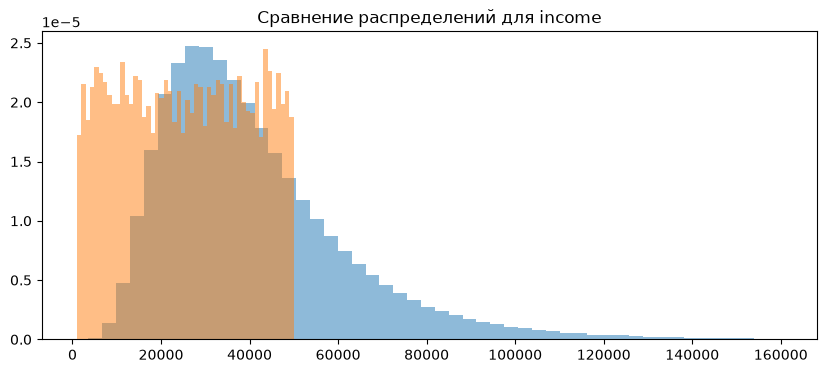

In [52]:
col = 'income'

pos_data = df.loc[(df[col] >= 0) & (df[col] <= df[col].quantile(0.99)), col]
neg_data = df.loc[df[col] < 0, col].abs()

plt.figure(figsize=(10, 4))
plt.hist(pos_data, bins=50, alpha=0.5, density=True)
plt.hist(neg_data, bins=50, alpha=0.5, density=True)
plt.title(f'Сравнение распределений для {col}')
plt.show()

Была гипотеза просто взять abs от отрицательных, но сейчас передумал, лучше просто отделить в отдельный признак

Ниже функция для подсчета нашей метрики

threshold берется из подсчета мат. ожидания прибыли
$$ 0.18 \cdot (1 - p) - 0.75 \cdot p$$
Выразив p мы получим 0.18/0.93

In [53]:
THRESHOLD = 0.18 / 0.93

def calculate_profit(y_true, y_pred_prob, credit_limits, threshold=THRESHOLD):
    issued = (y_pred_prob < threshold).astype(int)
    
    outcome_multiplier = 0.18 * (1 - y_true) - 0.75 * y_true
    
    total_profit = (issued * credit_limits * outcome_multiplier).sum()
    
    return total_profit

In [54]:
X = df[features].copy()
y = df[TARGET].values
limits = df['desired_credit_limit'].values

for c in cat_features:
    X[c] = X[c].astype('category')

X_train, X_val, y_train, y_val, limits_train, limits_val = train_test_split(
    X, y, limits, test_size=0.20, random_state=42, stratify=y
)

#baseline
model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    force_row_wise=True
)

model.fit(X_train, y_train)

val_probs = model.predict_proba(X_val)[:, 1]

val_auc = roc_auc_score(y_val, val_probs)
val_profit = calculate_profit(y_val, val_probs, limits_val)
approval_rate = (val_probs < (0.18 / 0.93)).mean() * 100

scaled_profit_100k = (val_profit / len(y_val)) * 100_000

print(f"ROC-AUC: {val_auc:.4f}")
print(f"Доля одобренных заявок: {approval_rate:.2f}%")
print(f"Прибыль на валидации (200k): {val_profit:,.2f}")
print(f"Ожидаемая прибыль на тесте (100k): {scaled_profit_100k:,.2f}")

ROC-AUC: 0.8375
Доля одобренных заявок: 43.94%
Прибыль на валидации (200k): 179,401,797.02
Ожидаемая прибыль на тесте (100k): 89,700,898.51


Ну можно уже и так оставить

In [55]:
def make_focused_features(data):
    df_feat = data.copy()
    df_feat['education_is_nan'] = df_feat['education'].isna().astype(int)
    
    df_feat['income_is_negative'] = (df_feat['income'] < 0).astype(int)
    df_feat['loan_is_negative'] = (df_feat['existing_loan_amount'] < 0).astype(int)
    df_feat['utilization_is_negative'] = (df_feat['credit_utilization'] < 0).astype(int)
    
    return df_feat

In [56]:
df_prep = make_focused_features(df)

model_features = [c for c in df_prep.columns if c not in ['client_id', 'default_within_1y']]

X = df_prep[model_features].copy()
y = df_prep['default_within_1y'].values
limits = df_prep['desired_credit_limit'].values

cat_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
for c in cat_features:
    X[c] = X[c].astype('category')

X_train, X_val, y_train, y_val, limits_train, limits_val = train_test_split(
    X, y, limits, test_size=0.20, random_state=42, stratify=y
)

print(f"Признаков на вход модели: {len(model_features)}")

Признаков на вход модели: 22


In [ ]:
def objective(trial):
    params = {
        'n_estimators': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 50),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'min_child_samples': trial.suggest_int('min_child_samples', 30, 150),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'random_state': 42,
        'n_jobs': -1,
        'force_row_wise': True
    }
    
    model = LGBMClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_X=X_val,
        eval_y=y_val,
        eval_metric='binary_logloss',
        callbacks=[early_stopping(stopping_rounds=30, verbose=False)]
    )
    trial.set_user_attr('best_iteration', model.best_iteration_)
    
    val_probs = model.predict_proba(X_val)[:, 1]
    
    profit = calculate_profit(y_val, val_probs, limits_val, threshold=THRESHOLD)
    return profit

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print(f"Максимальная прибыль на валидации: {study.best_value:,.2f}")
print("Лучшие параметры:")
print(f"n_estimators: {study.best_trial.user_attrs['best_iteration']}")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Максимальная прибыль на валидации: 180,772,470.06
Лучшие параметры:
n_estimators: 275
  learning_rate: 0.054880856619963364
  num_leaves: 28
  max_depth: 8
  min_child_samples: 32
  subsample: 0.7029412125881576
  colsample_bytree: 0.899243293151708


In [ ]:
final_params = study.best_params.copy()
final_params['n_estimators'] = study.best_trial.user_attrs['best_iteration']
final_params.update({
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1,
    'force_row_wise': True
})

model = LGBMClassifier(**final_params)
model.fit(X, y)

#THRESHOLD - порог одобрения
#calculate_profit - подсчет профита

Итоговая модель обученная на всех данных с оптимальными параметрами и небольшим изменением в признаках. Не было существенных изменений, так как сказано, что ООТ.csv сгенирирована таким же образом и дерево неплохо разбирается с нелинейными признаками. Ну и прибыль итоговую вроде я набираю.